<a href="https://colab.research.google.com/github/DaNa-cpu/abnormal-behavior-detection/blob/main/ped2_dataset_dataloader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCSD Ped2 - Dataset, DataLoader, transformari si impartirea datelor

**Impartirea datelor pe secvente video:**
- **train**: 13 secvente din setul Train (contine doar comportament normal)
- **val**: 3 secvente din setul Train (normale, folosite pentru monitorizarea pierderilor si salvarea modelului)
- **test**: cele 12 secvente oficiale din setul Test (contin atat cadre normale cat si anormale, cu etichete la nivel de cadru)

In [55]:
import os, glob, random, subprocess, tarfile
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## 1. Descarcare si dezarhivare date

In [56]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
DATA_DIR = "/content/data"
ARCHIVE = f"{DATA_DIR}/UCSD_Anomaly_Dataset.tar.gz"
URL = "http://www.svcl.ucsd.edu/projects/anomaly/UCSD_Anomaly_Dataset.tar.gz"
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.isdir(f"{DATA_DIR}/UCSD_Anomaly_Dataset.v1p2"):
    if not os.path.exists(ARCHIVE):
        subprocess.run(["wget", "-q", "-O", ARCHIVE, URL], check=True)
    with tarfile.open(ARCHIVE) as tar:
        tar.extractall(DATA_DIR)

PED2_ROOT = f"{DATA_DIR}/UCSD_Anomaly_Dataset.v1p2/UCSDped2"
print(os.listdir(PED2_ROOT))

['.DS_Store', 'Test', '._.DS_Store', 'Train']


## 2. Indexarea cadrelor si a etichetelor

Fiecare esantion este salvat sub forma: (cale_imagine, eticheta, nume_video, index_cadru).
Eticheta la test: un cadru este considerat anormal (1) daca masca de adnotare TestXXX_gt/NNN.bmp contine pixeli cu valori mai mari de 0.

In [58]:
def list_train_samples(root):
    samples = []
    for vdir in sorted(glob.glob(os.path.join(root, "Train", "Train[0-9][0-9][0-9]"))):
        name = os.path.basename(vdir)
        frames = sorted(glob.glob(os.path.join(vdir, "*.tif")))
        samples += [(f, 0, name, i) for i, f in enumerate(frames)]
    return samples


def list_test_samples(root):
    samples = []
    for vdir in sorted(glob.glob(os.path.join(root, "Test", "Test[0-9][0-9][0-9]"))):
        name = os.path.basename(vdir)
        frames = sorted(glob.glob(os.path.join(vdir, "*.tif")))
        masks = sorted(glob.glob(os.path.join(vdir + "_gt", "*.bmp")))
        assert len(frames) == len(masks), f"{name}: {len(frames)} cadre vs {len(masks)} masti"
        for i, (f, m) in enumerate(zip(frames, masks)):
            label = int(np.array(Image.open(m).convert("L")).max() > 0)
            samples.append((f, label, name, i))
    return samples


def split_train_val(train_samples, n_val_videos=3, seed=SEED):
    "n_val_videos pentru validare, restul pentru antrenare."
    videos = sorted({s[2] for s in train_samples})
    rng = random.Random(seed)
    rng.shuffle(videos)
    val_videos = set(videos[:n_val_videos])
    train = [s for s in train_samples if s[2] not in val_videos]
    val = [s for s in train_samples if s[2] in val_videos]
    return train, val

## 3. Setul de date si transformari

Preprocesare: transformare in grayscale, redimensionare spatiala si conversie in tensor scalat in intervalul [0, 1].
Nu utilizam augmentari deoarece modelul trebuie sa invete exclusiv perspectiva si distributia scenei fixe.

In [59]:
IMG_H, IMG_W = 128, 192

def get_transform(img_size=(IMG_H, IMG_W)):
    return transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize(img_size),
        transforms.ToTensor(),
    ])


class UCSDPed2Frames(Dataset):
    "(imagine[1,H,W], eticheta, nume_video, index_cadru)"
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label, video, frame_idx = self.samples[idx]
        img = Image.open(path).convert("L")
        if self.transform is not None:
            img = self.transform(img)
        return img, label, video, frame_idx

## 4. Construirea seturilor de date si a incarcatoarelor

In [60]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

BATCH_SIZE = 64
NUM_WORKERS = 2

train_all = list_train_samples(PED2_ROOT)
test_samples = list_test_samples(PED2_ROOT)
train_samples, val_samples = split_train_val(train_all, n_val_videos=3)

tf = get_transform()
train_ds = UCSDPed2Frames(train_samples, tf)
val_ds = UCSDPed2Frames(val_samples, tf)
test_ds = UCSDPed2Frames(test_samples, tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

## 5. Verificarea structurii datelor

In [61]:
def summarize(name, ds):
    labels = np.array([s[1] for s in ds.samples])
    videos = sorted({s[2] for s in ds.samples})
    print(f"{name:5s}: {len(ds):5d} cadre | {len(videos):2d} video | "
          f"normale={int((labels == 0).sum())}, anormale={int((labels == 1).sum())}")

summarize("train", train_ds); summarize("val", val_ds); summarize("test", test_ds)
print("Video train:", sorted({s[2] for s in train_samples}))
print("Video val  :", sorted({s[2] for s in val_samples}))

assert not ({s[2] for s in train_samples} & {s[2] for s in val_samples})
assert len({s[2] for s in train_all}) == 16, "Ped2 ar trebui sa aiba 16 secvente de antrenare"
assert len({s[2] for s in test_samples}) == 12, "Ped2 ar trebui sa aiba 12 secvente de test"

imgs, labels, videos, fidx = next(iter(train_loader))
print("Batch:", imgs.shape, imgs.dtype, f"min={imgs.min():.3f} max={imgs.max():.3f}")

train:  2100 cadre | 13 video | normale=2100, anormale=0
val  :   450 cadre |  3 video | normale=450, anormale=0
test :  2010 cadre | 12 video | normale=362, anormale=1648
Video train: ['Train001', 'Train002', 'Train003', 'Train004', 'Train005', 'Train007', 'Train009', 'Train011', 'Train012', 'Train013', 'Train014', 'Train015', 'Train016']
Video val  : ['Train006', 'Train008', 'Train010']
Batch: torch.Size([64, 1, 128, 192]) torch.float32 min=0.129 max=0.808


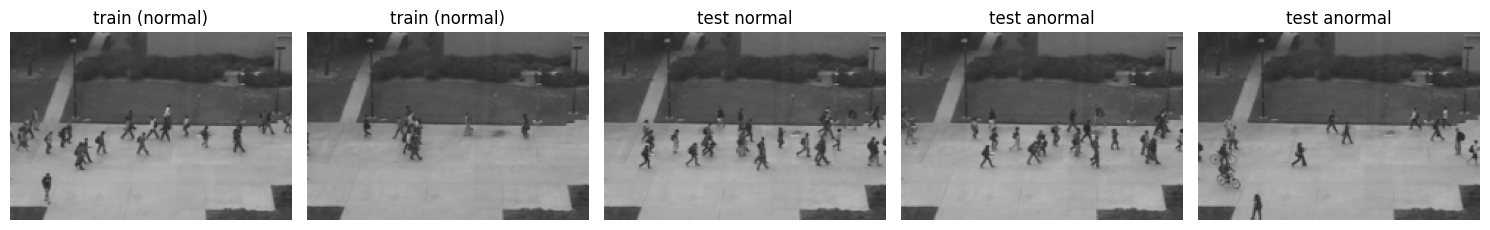

In [62]:
# Vizualizare: cadre normale (train) si cadre anormale (test)
anom = [i for i, s in enumerate(test_ds.samples) if s[1] == 1]
norm = [i for i, s in enumerate(test_ds.samples) if s[1] == 0]
picks = [("train (normal)", train_ds[0][0]), ("train (normal)", train_ds[len(train_ds) // 2][0]),
         ("test normal", test_ds[norm[0]][0]), ("test anormal", test_ds[anom[0]][0]),
         ("test anormal", test_ds[anom[len(anom) // 2]][0])]
fig, axes = plt.subplots(1, len(picks), figsize=(3 * len(picks), 3))
for ax, (title, im) in zip(axes, picks):
    ax.imshow(im.squeeze(0), cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Autoencoder convolutional pentru detectia anomaliilor

### Principiul de functionare:
1. **Antrenare**: Modelul este antrenat doar pe cadre normale. El invata sa comprime si sa reconstruiasca aceste tipare repetitive (fundalul static, pietonii pe alee).
2. **Detectie**: In faza de test, cand intalneste un cadru cu elemente anormale (vehicule, biciclete), modelul va produce o eroare de reconstructie semnificativ mai mare.

### Structura straturilor:
- **Encoder**: Straturi convolutionale urmate de normalizare pe lot (BatchNorm2d), activari ReLU si straturi de pooling pentru reducerea dimensiunii spatiale.
- **Decoder**: Straturi de convolutie transpusa (ConvTranspose2d) si normalizare pentru a readuce imaginea la rezolutia originala, finalizand cu o activare Sigmoid.

In [63]:
import torch.nn as nn

class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()

        # Encoder: Input (1, 128, 192)
        self.encoder = nn.Sequential(
            # Primul bloc convolutional
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                                         # -> (16, 64, 96)

            # Al doilea bloc convolutional
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                                         # -> (32, 32, 48)
            nn.Dropout(0.1),

            # Al treilea bloc convolutional
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)                                          # -> (64, 16, 24)
        )

        # Decoder: Reconstruction inapoi la (1, 128, 192)
        self.decoder = nn.Sequential(
            # Primul bloc de decompressie
            nn.ConvTranspose2d(in_channels=64, out_channels=32, kernel_size=2, stride=2),   # -> (32, 32, 48)
            nn.BatchNorm2d(32),
            nn.ReLU(),

            # Al doilea bloc de decompressie
            nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=2, stride=2),   # -> (16, 64, 96)
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Dropout(0.1),

            # Al treilea bloc de decompressie pentru restaurarea dimensiunii originale
            nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=2, stride=2),    # -> (1, 128, 192)
            nn.Sigmoid() # Asigura output in intervalul [0, 1]
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed

# Instantierea modelului si verificarea output-ului
model = ConvAutoencoder().to(DEVICE)
print(model)

# Verificam arhitectura cu un tensor de test
with torch.no_grad():
    test_input = torch.randn(1, 1, 128, 192).to(DEVICE)
    test_output = model(test_input)
    print(f"\nDimensiune input:  {test_input.shape}")
    print(f"Dimensiune output: {test_output.shape}")

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Dropout(p=0.1, inplace=False)
    (9): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2,

## 7. Functia de antrenare cu salvare automata si early stopping

Antrenarea utilizeaza eroarea patratica medie (MSE Loss) drept functie de cost si optimizatorul Adam.
Am integrat un mecanism de oprire timpurie (Early Stopping) care monitorizeaza pierderea de validare si salveaza automat cel mai bun model.

In [64]:
import torch.optim as optim
import copy

def train_model(model, train_loader, val_loader, epochs=10, lr=1e-3, device=DEVICE, patience=3):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'lr': []}
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        # Modul de antrenare
        model.train()
        train_loss = 0.0

        for imgs, _, _, _ in train_loader:
            imgs = imgs.to(device)

            # Pasul de predictie (reconstructie)
            outputs = model(imgs)
            loss = criterion(outputs, imgs)

            # Backpropagation si optimizare
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * imgs.size(0)

        train_loss /= len(train_loader.dataset)

        # Modul de evaluare pe datele de validare
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for imgs, _, _, _ in val_loader:
                imgs = imgs.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, imgs)
                val_loss += loss.item() * imgs.size(0)

        val_loss /= len(val_loader.dataset)

        # Obtinem rata curenta de invatare
        current_lr = optimizer.param_groups[0]['lr']

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['lr'].append(current_lr)

        print(f"Epoca [{epoch:02d}/{epochs:02d}] | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | LR: {current_lr:.6f}")

        # Logica de Early Stopping si salvarea celei mai bune stari
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0

            # Salvare checkpoint automat pentru cel mai bun model
            best_checkpoint = {
                'epoch': epoch,
                'state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'history': history,
                'torch_rng_state': torch.get_rng_state(),
                'cuda_rng_state': torch.cuda.get_rng_state() if torch.cuda.is_available() else None,
                'numpy_rng_state': np.random.get_state(),
                'random_rng_state': random.getstate()
            }
            torch.save(best_checkpoint, "best_autoencoder_checkpoint.pth")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early Stopping activat! Antrenarea s-a oprit la epoca {epoch} deoarece loss-ul de validare nu s-a imbunatatit timp de {patience} epoci.")
                break

    # Incarcam cele mai bune ponderi inapoi in model inainte de finalizare
    model.load_state_dict(best_model_wts)
    return history

## 8. Evaluarea reconstructiei si calculul scorurilor de anomalie

Pentru a evalua performanta, calculam eroarea patratica pentru fiecare pixel. Pentru a evita diluarea anomaliilor de catre fundalul static, selectam primii 10% cei mai afectati pixeli (Top-10%) pentru a stabili scorul de anomalie al fiecarui cadru.

In [65]:
def evaluate_model(model, test_loader, device=DEVICE):
    model.eval()
    criterion = nn.MSELoss(reduction='none')

    all_scores = []
    all_labels = []
    all_video_names = []
    all_frame_indices = []

    with torch.no_grad():
        for imgs, labels, video_names, frame_indices in test_loader:
            imgs = imgs.to(device)
            outputs = model(imgs)

            # Calculam eroarea patratica pentru fiecare pixel individual: (B, 1, H, W)
            pixel_errors = criterion(outputs, imgs)

            # In loc sa facem media pe tot cadrul, selectam primii 10% cei mai afectati pixeli (Top-K)
            # Acest lucru previne diluarea erorii de catre fundalul static reconstituit perfect
            B, C, H, W = pixel_errors.shape
            flat_errors = pixel_errors.view(B, -1) # Redimensionam la (B, H*W)

            num_pixels = flat_errors.size(1)
            k = int(num_pixels * 0.10) # Luam cei mai eronati 10% pixeli

            topk_errors, _ = torch.topk(flat_errors, k, dim=1)
            losses = topk_errors.mean(dim=1) # Media erorilor din regiunea de anomalie potentiala

            all_scores.extend(losses.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_video_names.extend(video_names)
            all_frame_indices.extend(frame_indices.numpy())

    return {
        'scores': np.array(all_scores),
        'labels': np.array(all_labels),
        'videos': all_video_names,
        'frames': np.array(all_frame_indices)
    }

## 9. Afisarea rezultatelor procesului de antrenare

In [66]:
def plot_training_results(history):
    plt.figure(figsize=(10, 6))
    plt.plot(history['train_loss'], label='Train Loss', color='blue', marker='o')
    plt.plot(history['val_loss'], label='Val Loss', color='red', marker='x')
    plt.title('Evolutia erorilor de antrenare si validare')
    plt.xlabel('Epoca')
    plt.ylabel('Loss (MSE)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()



## 10. Functii pentru salvarea si incarcarea checkpoint-urilor

In [67]:
import random

def save_checkpoint(state, filepath="checkpoint.pth"):
    """
    Salveaza starea curenta a antrenarii.
    """
    print(f"Se salveaza checkpoint-ul in: {filepath}")
    torch.save(state, filepath)

def load_checkpoint(filepath, model, optimizer=None, scheduler=None):
    """
    Incarca o stare salvata anterior si restaureaza configuratia modelului si a optimizatorului.
    """
    if not os.path.exists(filepath):
        print(f"Nu s-a gasit niciun checkpoint la calea: {filepath}")
        return None

    print(f"Se incarca checkpoint-ul din: {filepath}")
    checkpoint = torch.load(filepath, map_location=DEVICE)

    model.load_state_dict(checkpoint['state_dict'])

    if optimizer is not None and 'optimizer_state_dict' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    if scheduler is not None and 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    # Restaurarea starilor RNG pentru reproductibilitate
    if 'torch_rng_state' in checkpoint:
        torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
    if 'cuda_rng_state' in checkpoint and torch.cuda.is_available():
        torch.cuda.set_rng_state(checkpoint['cuda_rng_state'].cpu())
    if 'numpy_rng_state' in checkpoint:
        np.random.set_state(checkpoint['numpy_rng_state'])
    if 'random_rng_state' in checkpoint:
        random.setstate(checkpoint['random_rng_state'])

    print(f"Checkpoint incarcat cu succes! Reluam de la epoca {checkpoint['epoch']}")
    return checkpoint


## 11. Initializarea si rularea procesului de antrenare

--- Incepe antrenarea modelului optimizat ---
Epoca [01/15] | Train Loss: 0.016660 | Val Loss: 0.011196 | LR: 0.001000
Epoca [02/15] | Train Loss: 0.005766 | Val Loss: 0.003062 | LR: 0.001000
Epoca [03/15] | Train Loss: 0.004530 | Val Loss: 0.002268 | LR: 0.001000
Epoca [04/15] | Train Loss: 0.003931 | Val Loss: 0.001954 | LR: 0.001000
Epoca [05/15] | Train Loss: 0.003492 | Val Loss: 0.001782 | LR: 0.001000
Epoca [06/15] | Train Loss: 0.003147 | Val Loss: 0.001544 | LR: 0.001000
Epoca [07/15] | Train Loss: 0.002866 | Val Loss: 0.001386 | LR: 0.001000
Epoca [08/15] | Train Loss: 0.002646 | Val Loss: 0.001307 | LR: 0.001000
Epoca [09/15] | Train Loss: 0.002463 | Val Loss: 0.001242 | LR: 0.001000
Epoca [10/15] | Train Loss: 0.002311 | Val Loss: 0.001186 | LR: 0.001000
Epoca [11/15] | Train Loss: 0.002189 | Val Loss: 0.001131 | LR: 0.001000
Epoca [12/15] | Train Loss: 0.002082 | Val Loss: 0.001086 | LR: 0.001000
Epoca [13/15] | Train Loss: 0.001993 | Val Loss: 0.001047 | LR: 0.001000
Epoca

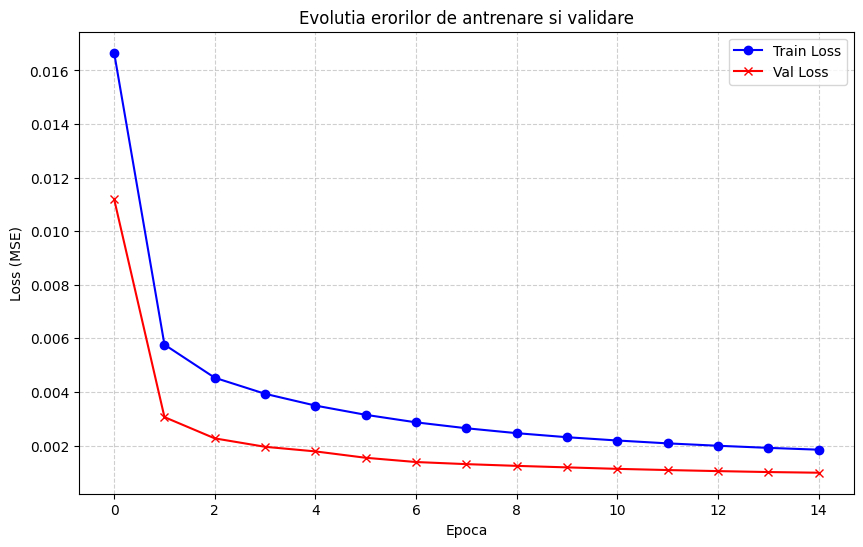

In [68]:
# 1. Initializare model si optimizator cu noua arhitectura
model = ConvAutoencoder().to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. Antrenare model cu noile functionalitati (Scheduler si Early Stopping integrat)
print("--- Incepe antrenarea modelului optimizat ---")
history = train_model(model, train_loader, val_loader, epochs=15, lr=1e-3, device=DEVICE, patience=3)

# 3. Salvare checkpoint final cu toate starile necesare pentru reproductibilitate
checkpoint_state = {
    'epoch': len(history['train_loss']),
    'state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'history': history,
    'torch_rng_state': torch.get_rng_state(),
    'cuda_rng_state': torch.cuda.get_rng_state() if torch.cuda.is_available() else None,
    'numpy_rng_state': np.random.get_state(),
    'random_rng_state': random.getstate()
}
save_checkpoint(checkpoint_state, filepath="final_autoencoder_checkpoint.pth")

# 4. Vizualizare curbe de pierdere (Loss) si a Ratei de Invatare (Learning Rate)
print("\n--- Afisare grafic pierderi si rata de invatare ---")
plot_training_results(history)

--- Incepe evaluarea pe setul de test (Top-10% eroare reconstructie) ---

--- Rezultate evaluare ---
Numar total de cadre testate: 2010
Frame-level ROC-AUC: 0.7638


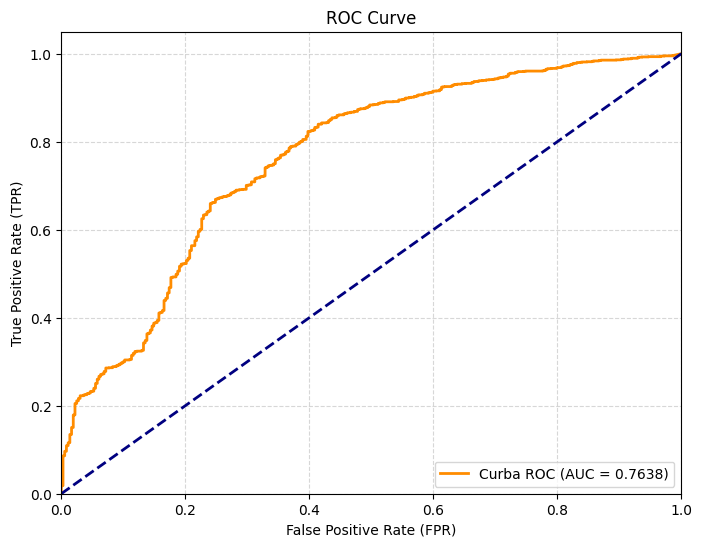

In [70]:
# 1. Evaluarea pe intregul set de test folosind modelul optimizat
print("--- Incepe evaluarea pe setul de test (Top-10% eroare reconstructie) ---")
test_results = evaluate_model(model, test_loader, device=DEVICE)

raw_scores = test_results['scores']
labels = test_results['labels']
video_names = test_results['videos']

# 2. Normalizarea locala min-max a scorurilor pe fiecare video in parte
normalized_scores = np.zeros_like(raw_scores)
unique_videos = sorted(list(set(video_names)))

for video in unique_videos:
    indices = [i for i, v in enumerate(video_names) if v == video]
    video_raw = raw_scores[indices]
    v_min = video_raw.min()
    v_max = video_raw.max()
    if v_max - v_min > 1e-8:
        normalized_scores[indices] = (video_raw - v_min) / (v_max - v_min)
    else:
        normalized_scores[indices] = 0.0

# 3. Calcularea curbei ROC si a indicatorului AUC la nivel de cadru
from sklearn.metrics import roc_curve, auc
fpr, tpr, thresholds = roc_curve(labels, normalized_scores)
roc_auc = auc(fpr, tpr)

print(f"\n--- Rezultate evaluare ---")
print(f"Numar total de cadre testate: {len(labels)}")
print(f"Frame-level ROC-AUC: {roc_auc:.4f}")

# 4. Afisarea exclusiva a curbei ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"Curba ROC (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()